In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/shopify_stock.csv")


In [6]:
df["date"] = pd.to_datetime(df["date"], utc=True)
df = df.sort_values("date")

In [8]:
df["Daily_Return"] = ((df["close"] - df["open"]) / df["open"]) * 100

In [10]:
df["MA20"] = df["close"].rolling(20).mean()
df["MA50"] = df["close"].rolling(50).mean()

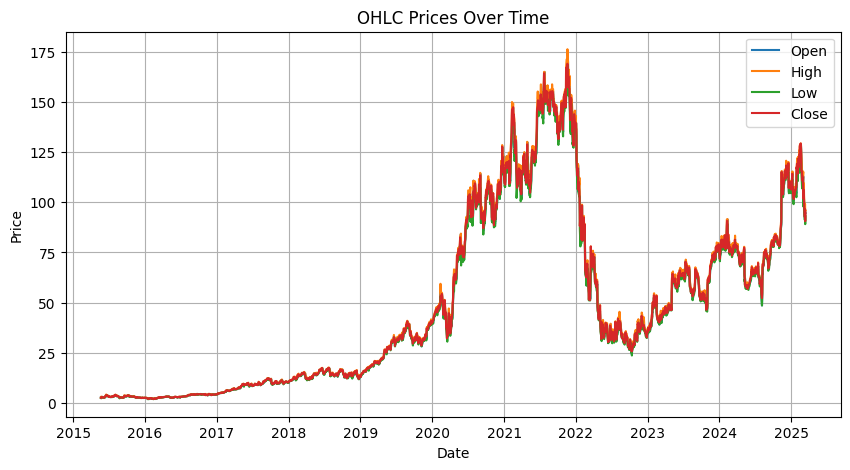

In [12]:
plt.figure(figsize=(10,5))
plt.plot(df["date"], df["open"], label="Open")
plt.plot(df["date"], df["high"], label="High")
plt.plot(df["date"], df["low"], label="Low")
plt.plot(df["date"], df["close"], label="Close")

plt.title("OHLC Prices Over Time")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid()
plt.show()

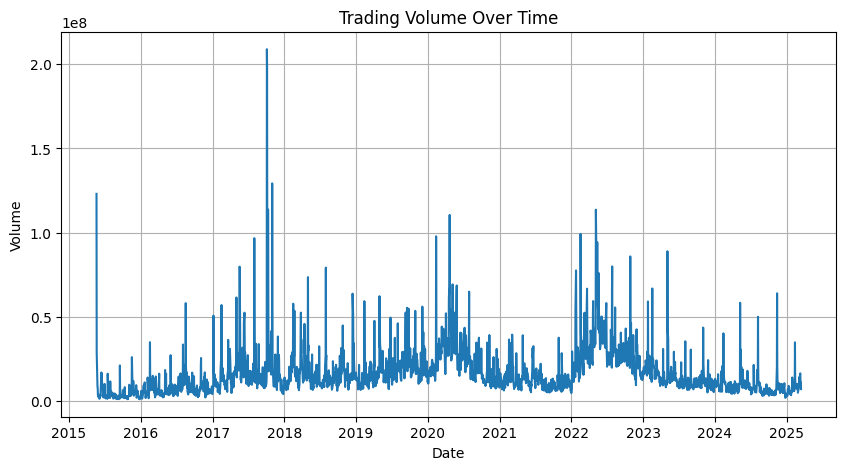

In [15]:
plt.figure(figsize=(10,5))
plt.plot(df["date"], df["volume"])

plt.title("Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.grid()
plt.show()

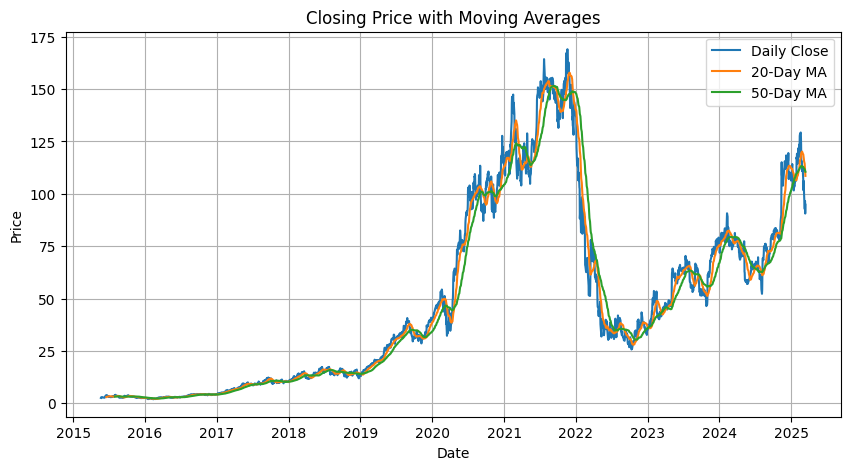

In [17]:
plt.figure(figsize=(10,5))
plt.plot(df["date"], df["close"], label="Daily Close")
plt.plot(df["date"], df["MA20"], label="20-Day MA")
plt.plot(df["date"], df["MA50"], label="50-Day MA")

plt.title("Closing Price with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid()
plt.show()

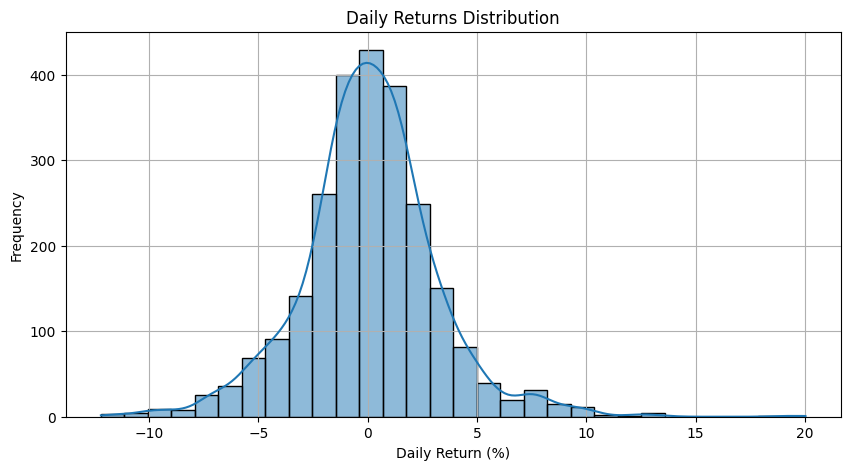

In [18]:
plt.figure(figsize=(10,5))

sns.histplot(df["Daily_Return"].dropna(),
             bins=30, kde=True)

plt.title("Daily Returns Distribution")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.grid()
plt.show()


In [19]:
mean_return = df["Daily_Return"].mean()
std_return = df["Daily_Return"].std()
max_return = df["Daily_Return"].max()
min_return = df["Daily_Return"].min()

In [21]:
high_volatility = df[
    abs(df["Daily_Return"]) > 2 * std_return
]

print("----- FINANCIAL SUMMARY REPORT -----")

print("Average Daily Return:", round(mean_return, 2), "%")
print("Return Standard Deviation:", round(std_return, 2), "%")
print("Maximum Daily Return:", round(max_return, 2), "%")
print("Minimum Daily Return:", round(min_return, 2), "%")

print("\nHigh-Volatility Periods:")
print(high_volatility[["date", "Daily_Return"]])

----- FINANCIAL SUMMARY REPORT -----
Average Daily Return: 0.09 %
Return Standard Deviation: 3.12 %
Maximum Daily Return: 20.02 %
Minimum Daily Return: -12.2 %

High-Volatility Periods:
                          date  Daily_Return
0    2015-05-21 04:00:00+00:00     -8.285710
1    2015-05-22 04:00:00+00:00      8.592250
3    2015-05-27 04:00:00+00:00    -10.335830
12   2015-06-09 04:00:00+00:00      6.381384
14   2015-06-11 04:00:00+00:00      7.862407
...                        ...           ...
2387 2024-11-13 05:00:00+00:00      7.060462
2411 2024-12-18 05:00:00+00:00     -7.663822
2423 2025-01-07 05:00:00+00:00     -7.067017
2436 2025-01-28 05:00:00+00:00      7.752291
2453 2025-02-21 05:00:00+00:00     -7.699680

[146 rows x 2 columns]


In [22]:
if std_return < 1:
    print("\nStock Stability: Highly Stable")
elif std_return < 2:
    print("\nStock Stability: Moderately Stable")
else:
    print("\nStock Stability: Highly Volatile")


Stock Stability: Highly Volatile
